---
title: "Exploratory Analysis and Data Visualisation"
subtitle: "Reading the HarborLink invoice table"
jupyter: data-extraction-lesson
fig-width: 8
fig-height: 4.4
---

In [1]:
from pathlib import Path
import os

if not Path("data/processed/harborlink_invoices.csv").exists():
    os.chdir(Path("..").resolve())

print("Working directory:", Path.cwd())

Working directory: /Users/heuchennecedric/Documents/data-extraction-lesson


## Learning objectives

The starting point is **one invoice-level table**. The aim is to read it.

After working through this document you should be able to:

1. State a business question before choosing a graph.
2. Distinguish counts, rates and distributions, and say which one answers the question.
3. Build standard plots with **matplotlib** and **seaborn**, and explain each important argument.
4. Interpret a graph in business language, including what it does *not* show.
5. Treat missing values, small samples and process-generated variables as interpretation problems, not as decoration.
6. Take a short, honest summary to a finance or operations meeting.
7. Place one customer on the panel: a payment timeline, then that customer's values on the distributions of the other customers.

Important commands are explained the first time they appear. The document does not fit statistical models or machine-learning algorithms.

The file is `data/processed/harborlink_invoices.csv`. It was built by joining HarborLink invoices, customers, subscriptions, payments, CRM summaries and the September API snapshot. One row is still **one invoice**.

## The HarborLink question

HarborLink still wants to understand late payments. Elena Vargas, customer 1827, has an unpaid September invoice of EUR 49.90. That is one case. Exploratory analysis asks what the **table as a whole** looks like.

Useful questions:

- How many invoices are paid, unpaid or overdue?
- Is non-payment concentrated in some plans, segments or countries?
- How quickly do customers pay when they do pay?
- Did something change over time, or is September special because it is the current month?
- Do CRM messages tell us something we did not already know from the payment status?

A graph is a tool for those questions. It is not a destination.

```{mermaid}
flowchart LR
    A[Invoice-level DataFrame] --> B[Question]
    B --> C[Choice of summary]
    C --> D[Graph]
    D --> E[Interpretation]
    E --> F[Next question or decision]
```

## Part 1 — What we are looking at, and what a graph is for

### Load the analysis table

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

invoices = pd.read_csv(
    "data/processed/harborlink_invoices.csv",
    parse_dates=["invoice_date", "due_date", "payment_date", "signup_date"],
)
invoices.shape

(3325, 31)

- `pandas` loads the table.
- `numpy` is used later for a few numerical summaries.
- `matplotlib.pyplot` is the general plotting library. The conventional short name is `plt`.
- `seaborn` is a library built on matplotlib. It is convenient for statistical graphs (counts, means, boxplots) from a DataFrame. The conventional short name is `sns`.
- `sns.set_theme(...)` chooses a readable default: a white background with a light grid. It does not change the data.

`read_csv` returns a DataFrame. `parse_dates` turns the date columns into dates, so that time plots and delays can be computed. `shape` is the pair `(n_rows, n_columns)`: a little over three thousand invoices, and about thirty variables.

In [3]:
invoices.head()

,invoice_id,customer_id,subscription_id,order_id,invoice_date,due_date,amount,status,period,customer_name,...,n_reminders,n_complaints,n_payment_issues,n_emails,status_api,days_to_due,days_to_pay,paid_after_due,is_outstanding,tenure_months
0,INV-202411-3021,3021,SUB-3021,ORD-202411-3021,2024-11-01,2024-11-15,19.9,overdue,2024-11,Samir Ibrahim,...,1,1,1,1,NaN,14,NaN,False,True,0
1,INV-202411-3038,3038,SUB-3038,ORD-202411-3038,2024-11-01,2024-11-15,29.9,paid,2024-11,Rosa Ortiz,...,0,0,0,0,NaN,14,11.0,False,False,0
2,INV-202411-3073,3073,SUB-3073,ORD-202411-3073,2024-11-01,2024-11-15,19.9,paid,2024-11,Tina Janssens,...,0,0,0,0,NaN,14,4.0,False,False,0
3,INV-202411-3220,3220,SUB-3220,ORD-202411-3220,2024-11-01,2024-11-15,29.9,paid,2024-11,Willem Gatti,...,0,0,0,1,NaN,14,20.0,True,False,0
4,INV-202412-3001,3001,SUB-3001,ORD-202412-3001,2024-12-01,2024-12-15,19.9,paid,2024-12,Ulrich Engel,...,0,0,0,0,NaN,14,6.0,False,False,1


Each row is one billing cycle. `customer_id` 1827 is Elena; her September invoice is still `INV-2026-0901`. Columns such as `n_payment_issues`, `is_outstanding` and `tenure_months` already sit on that row. The task now is to **look** at the table, not to join further sources.

In [4]:
invoices[["invoice_id", "customer_name", "period", "amount", "payment_status", "is_outstanding"]].head()

,invoice_id,customer_name,period,amount,payment_status,is_outstanding
0,INV-202411-3021,Samir Ibrahim,2024-11,19.9,overdue,True
1,INV-202411-3038,Rosa Ortiz,2024-11,29.9,paid,False
2,INV-202411-3073,Tina Janssens,2024-11,19.9,paid,False
3,INV-202411-3220,Willem Gatti,2024-11,29.9,paid,False
4,INV-202412-3001,Ulrich Engel,2024-12,19.9,paid,False


### Observations, variables, and types

For EDA, three labels are enough:

| Kind | HarborLink examples | Typical graphs |
| --- | --- | --- |
| Categorical | `payment_status`, `subscription_type`, `country` | bars of counts or rates |
| Numerical | `amount`, `days_to_pay`, `n_interactions` | histogram, boxplot, scatter |
| Date / period | `invoice_date`, `period` | line over time |
| Binary | `is_outstanding`, `paid_after_due` | rate (mean of 0/1) |

`is_outstanding` is a Boolean: `True` when the payment is unpaid or overdue. The **mean** of a Boolean is the proportion of `True`. That is the outstanding rate.

In [5]:
invoices["payment_status"].value_counts()

payment_status
paid       3108
overdue     172
unpaid       45
Name: count, dtype: int64

In [6]:
invoices["is_outstanding"].mean()

np.float64(0.06526315789473684)

`value_counts()` counts rows in each category. About 3,100 invoices are paid. A little over 200 are not. The outstanding **rate** is about 6.5%. Counts and rates answer different questions: “how many problems do we have?” versus “how frequent is the problem?”

The three values of `payment_status` are a snapshot on **12 September 2026**. They do not mean the same thing:

| Status | What it means in this table |
| --- | --- |
| `paid` | A `payment_date` is recorded. That includes invoices paid **after** the due date. Late payment that was eventually recorded stays `paid`; it does not become `overdue`. |
| `unpaid` | No payment is recorded, and the due date has **not** yet passed. Here, all unpaid invoices are September invoices due on 15 September. |
| `overdue` | No payment is recorded, and the due date **has** already passed. There is no `payment_date`. `overdue` is not “paid late”; paid-late invoices are `paid` with `paid_after_due = True`. |

So `overdue` means: as of the snapshot, this invoice was never recorded as paid. For a closed month, that is an invoice that remained without a payment.

### Missing values are already an interpretation

In [7]:
invoices.isna().sum()[invoices.isna().sum() > 0]

customer_segment     116
payment_date         217
status_api          3085
days_to_pay          217
dtype: int64

Three missings matter, and they do not mean the same thing:

- `payment_date` and `days_to_pay` are missing when there was **no payment**. That is the outcome we study, not a data accident.
- `status_api` is missing for every invoice that is not in the September snapshot. The API does not cover history.
- `customer_segment` is missing for 10 customers in the customer CSV (the same empty cells appear in the Excel customer sheet). Those 10 customers produce 116 invoice rows without a segment. The gap is in the customer file, not in the invoice file. Keep it as a category called `unknown`, rather than silently dropping the rows.

In [8]:
invoices["segment"] = invoices["customer_segment"].fillna("unknown")
invoices["segment"].value_counts()

segment
smb           1939
mid-market     892
enterprise     378
unknown        116
Name: count, dtype: int64

`fillna("unknown")` replaces missing segment labels by an explicit word. The invoices stay in the table. If we dropped them, we would hide a data-quality issue and slightly change the outstanding rate.

### Matplotlib and seaborn, in one picture

A matplotlib **figure** is the whole image. An **axes** is the drawing area inside it: the panel that will contain the bars or points, with the scale marks and numbers along the sides (the *ticks*). Seaborn draws onto that axes. We will almost always write:

```python
fig, ax = plt.subplots()
sns.someplot(..., ax=ax)
ax.set_xlabel("...")
ax.set_ylabel("...")
ax.set_title("...")
```

- `plt.subplots()` creates the figure and one axes. It **returns** both; we store them in `fig` and `ax`.
- Seaborn’s plotting functions have an argument also called `ax`. Writing `ax=ax` means: use our drawing area `ax` as the value of seaborn’s `ax` argument, so the plot is drawn on the figure we just created rather than on some other plot.
- `set_xlabel` / `set_ylabel` name the axes in words a colleague can read.
- The title should state the **claim of the picture**, not the command that produced it.

### First graph: how many invoices in each payment status?

The first business question is simply: what is the current mix of statuses?

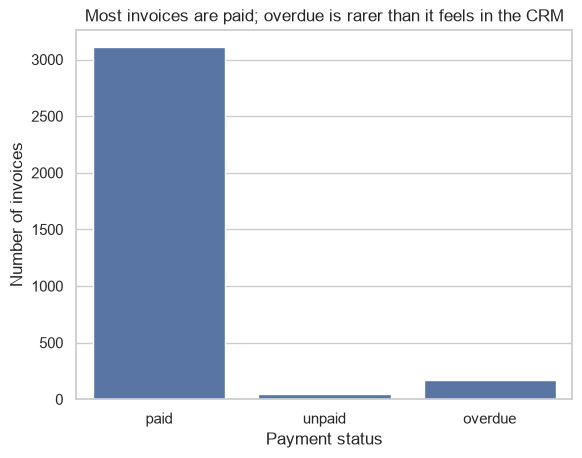

In [9]:
#| fig-cap: "Number of HarborLink invoices by payment status."
fig, ax = plt.subplots()
sns.countplot(
    data=invoices,
    x="payment_status",
    order=["paid", "unpaid", "overdue"],
    ax=ax,
)
ax.set_xlabel("Payment status")
ax.set_ylabel("Number of invoices")
ax.set_title("Most invoices are paid; overdue is rarer than it feels in the CRM")
plt.show()

- `sns.countplot` counts rows.
- `data=invoices` is the DataFrame.
- `x="payment_status"` places the category on the horizontal axis. Each bar is one status.
- `order=[...]` fixes the order. Without it, seaborn would follow the order of appearance in the file, which is not a story.

**Interpretation.** Paid invoices dominate. That is expected for a subscription business: most bills are collected. The operational attention sits in the two smaller bars. They are not interchangeable. Unpaid invoices are still inside the payment window. Overdue invoices are closed-cycle bills with **no payment recorded** in the table. A graph that lumped them together would mix “still waiting” with “still not paid after the due date”.

Invoices paid after the due date do **not** appear in the overdue bar. They remain `paid`. Elena’s September invoice belongs to the unpaid bar: her due date is 15 September and the extract is dated 12 September.

## Part 2 — Distributions, rates and comparisons

### Do not plot a number before asking what it can be

`amount` looks numerical. A histogram is the reflex.

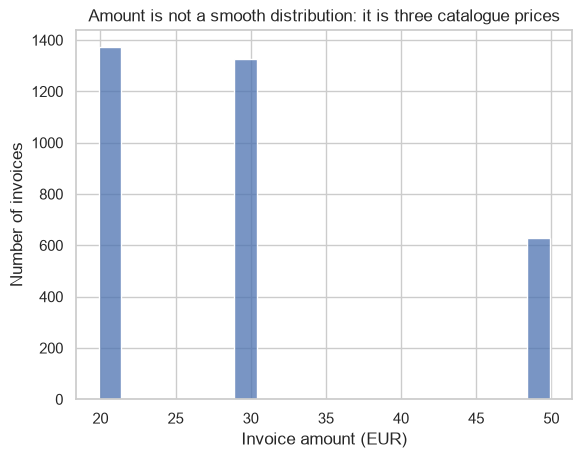

In [10]:
#| fig-cap: "Invoice amounts. The three spikes are the three HarborLink plans."
fig, ax = plt.subplots()
sns.histplot(data=invoices, x="amount", bins=20, ax=ax)
ax.set_xlabel("Invoice amount (EUR)")
ax.set_ylabel("Number of invoices")
ax.set_title("Amount is not a smooth distribution: it is three catalogue prices")
plt.show()

- `sns.histplot` counts how many rows fall into intervals of `x`.
- `bins=20` asks for twenty intervals. The exact number is less important than the shape.

**Interpretation.** There are no amounts between the spikes. HarborLink does not bill “around 30 euros”. It bills **starter 19.90**, **standard 29.90** and **premium 49.90**. A histogram was the wrong default. The honest graph is a bar of plans.

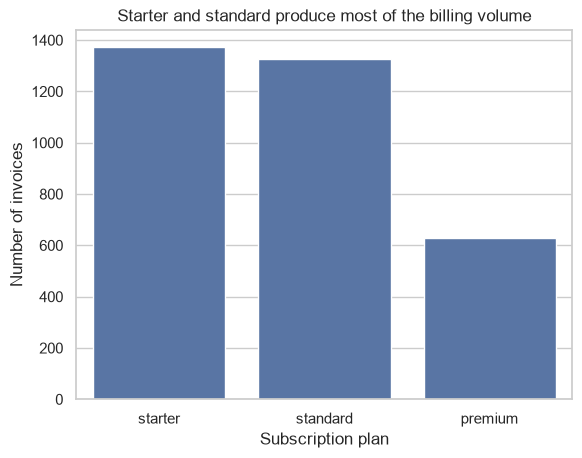

In [11]:
#| fig-cap: "Number of invoices by subscription plan."
fig, ax = plt.subplots()
sns.countplot(
    data=invoices,
    x="subscription_type",
    order=["starter", "standard", "premium"],
    ax=ax,
)
ax.set_xlabel("Subscription plan")
ax.set_ylabel("Number of invoices")
ax.set_title("Starter and standard produce most of the billing volume")
plt.show()

Premium is the smallest group of invoices. If premium later has a *lower outstanding rate*, that rate is estimated on fewer rows. Sample size must travel with the comparison.

### Counts answer volume; rates answer risk

How many outstanding invoices come from SMB customers?

In [12]:
outstanding = invoices[invoices["is_outstanding"]]
outstanding["segment"].value_counts()

segment
smb           132
mid-market     58
enterprise     18
unknown         9
Name: count, dtype: int64

Most outstanding invoices are SMB. That does **not** yet mean SMB customers pay worse. SMB is also the largest group, so they contribute more of everything.

The right comparison is the **rate**: the share of invoices that are outstanding inside each segment.

In [13]:
rate_by_segment = (
    invoices.groupby("segment")["is_outstanding"]
    .agg(n_invoices="size", n_outstanding="sum", rate="mean")
    .reindex(["smb", "mid-market", "enterprise", "unknown"])
)
rate_by_segment

,n_invoices,n_outstanding,rate
segment,,,
smb,1939,132,0.068076
mid-market,892,58,0.065022
enterprise,378,18,0.047619
unknown,116,9,0.077586


- `groupby("segment")` splits the table.
- `"is_outstanding"` is the series we summarise.
- `size` is the number of invoices.
- `sum` counts `True` values.
- `mean` is the outstanding rate.
- `reindex` puts the rows in a readable order.

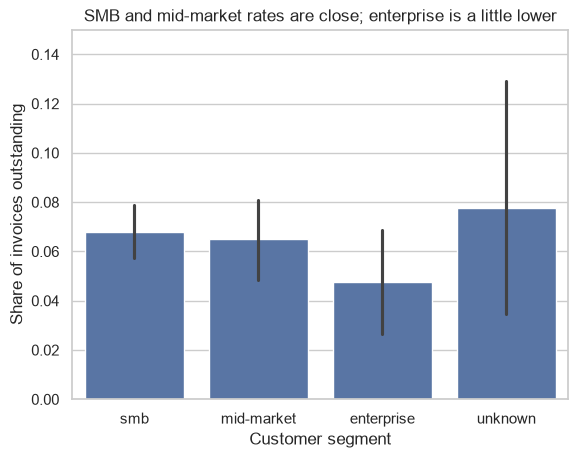

In [14]:
#| fig-cap: "Outstanding invoice rate by customer segment. The bar is a mean of a 0/1 variable."
fig, ax = plt.subplots()
sns.barplot(
    data=invoices,
    x="segment",
    y="is_outstanding",
    order=["smb", "mid-market", "enterprise", "unknown"],
    errorbar=("ci", 95),
    ax=ax,
)
ax.set_xlabel("Customer segment")
ax.set_ylabel("Share of invoices outstanding")
ax.set_title("SMB and mid-market rates are close; enterprise is a little lower")
ax.set_ylim(0, 0.15)
plt.show()

- `y="is_outstanding"` asks seaborn for the **mean** of that column in each `x` group.
- `errorbar=("ci", 95)` draws a 95% confidence interval around that mean. If the interval is wide, a small difference between bars is not a reliable finding.
- `set_ylim(0, 0.15)` starts the vertical axis at zero. Cutting the axis at 0.04 and 0.08 would make a 1–2 point gap look dramatic.

**Interpretation.** Enterprise invoices are outstanding a little less often (around 5%) than SMB or mid-market (around 6.5–7%). The unknown-segment group is small and slightly higher. The gaps are modest. A slide that said “SMB is the problem segment” would overstate what the table supports. What *is* true is that SMB generates most of the **workload**, because it is the largest volume.

The same logic for the plan:

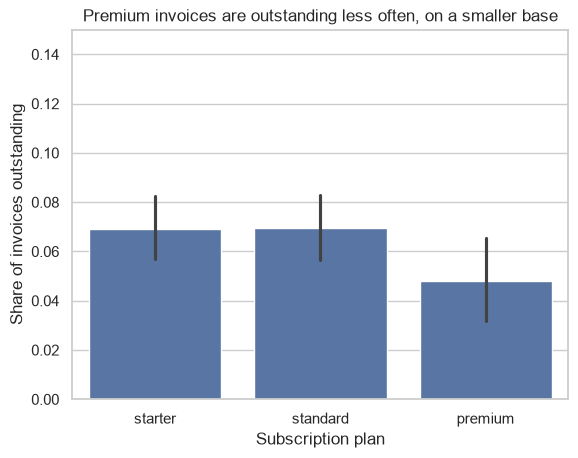

In [15]:
#| fig-cap: "Outstanding invoice rate by subscription plan."
fig, ax = plt.subplots()
sns.barplot(
    data=invoices,
    x="subscription_type",
    y="is_outstanding",
    order=["starter", "standard", "premium"],
    errorbar=("ci", 95),
    ax=ax,
)
ax.set_xlabel("Subscription plan")
ax.set_ylabel("Share of invoices outstanding")
ax.set_title("Premium invoices are outstanding less often, on a smaller base")
ax.set_ylim(0, 0.15)
plt.show()

**Interpretation.** Starter and standard look alike. Premium is lower, with a wider interval because there are fewer premium invoices. We may still treat premium as a milder risk group, but we should not invent a large commercial story from a two-point gap.

### How fast do customers pay when they pay?

`days_to_pay` is defined only for paid invoices. Plotting it on the full table would mix real delays with missing values.

In [16]:
paid = invoices.loc[invoices["payment_status"] == "paid"].copy()
paid["days_to_pay"].describe()

count    3108.000000
mean        9.653153
std         5.453142
min         2.000000
25%         5.000000
50%         9.000000
75%        12.000000
max        24.000000
Name: days_to_pay, dtype: float64

`describe()` summarises a numerical column: count, mean, quartiles, minimum, maximum. Among paid invoices, the typical delay is about 9–10 days after the invoice date. The slowest recorded payments take 24 days.

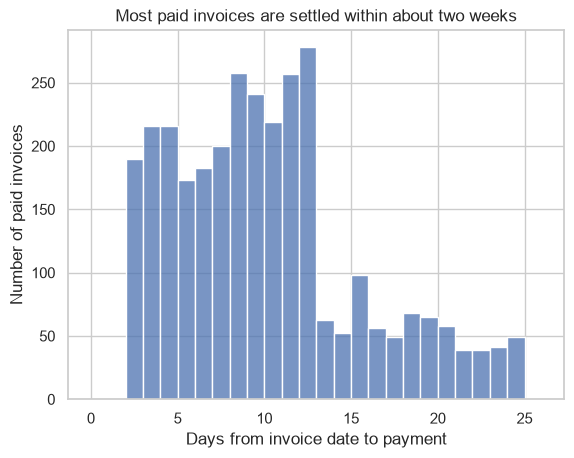

In [17]:
#| fig-cap: "Distribution of days from invoice date to payment, paid invoices only."
fig, ax = plt.subplots()
sns.histplot(data=paid, x="days_to_pay", bins=range(0, 27), ax=ax)
ax.set_xlabel("Days from invoice date to payment")
ax.set_ylabel("Number of paid invoices")
ax.set_title("Most paid invoices are settled within about two weeks")
plt.show()

`bins=range(0, 27)` puts a bar on each integer day. That is appropriate because delays are stored as whole days.

**Interpretation.** Collection is generally fast. The right-hand tail is the group that pays after the due date even though the invoice eventually becomes `paid`. That group is not “outstanding” in the snapshot, but it is operationally late.

In [18]:
paid["paid_after_due"].mean()

np.float64(0.1714929214929215)

About 17% of *paid* invoices were settled after the due date. A dashboard that only shows `overdue` would miss this milder form of lateness.

A boxplot compares the same delay across plans:

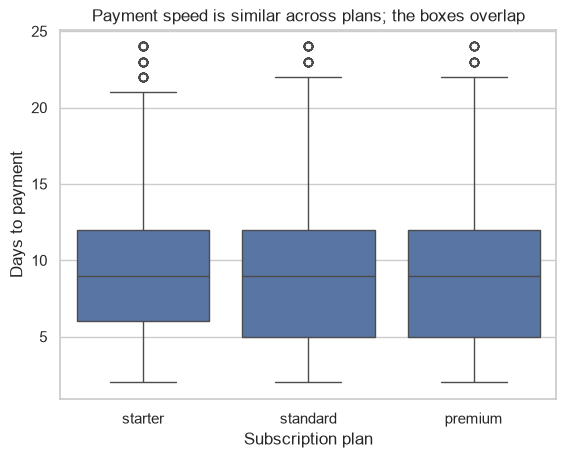

In [19]:
#| fig-cap: "Days to payment by plan, among paid invoices."
fig, ax = plt.subplots()
sns.boxplot(
    data=paid,
    x="subscription_type",
    y="days_to_pay",
    order=["starter", "standard", "premium"],
    ax=ax,
)
ax.set_xlabel("Subscription plan")
ax.set_ylabel("Days to payment")
ax.set_title("Payment speed is similar across plans; the boxes overlap")
plt.show()

- The box runs from the 25th to the 75th percentile.
- The line inside the box is the median.
- The whiskers cover the more extreme typical values; points beyond them are plotted individually.

**Interpretation.** The three boxes sit on top of one another. If finance wanted faster cash, changing the mix of plans would not be the first lever suggested by this picture.

### Country: look at the sample size before the ranking

In [20]:
rate_by_country = (
    invoices.groupby("country")["is_outstanding"]
    .agg(n_invoices="size", rate="mean")
    .sort_values("rate", ascending=False)
)
rate_by_country

,n_invoices,rate
country,,
BE,472,0.080508
DE,316,0.075949
LU,541,0.072089
NL,423,0.068558
ES,437,0.059497
IT,387,0.056848
FR,515,0.052427
IE,234,0.051282


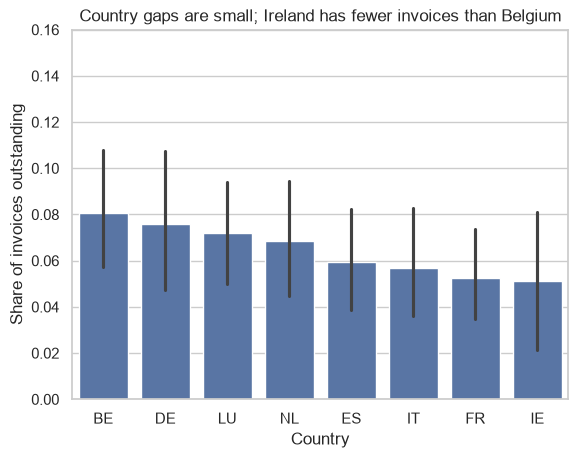

In [21]:
#| fig-cap: "Outstanding rate by country, with 95% confidence intervals."
fig, ax = plt.subplots()
sns.barplot(
    data=invoices,
    x="country",
    y="is_outstanding",
    order=rate_by_country.index,
    errorbar=("ci", 95),
    ax=ax,
)
ax.set_xlabel("Country")
ax.set_ylabel("Share of invoices outstanding")
ax.set_title("Country gaps are small; Ireland has fewer invoices than Belgium")
ax.set_ylim(0, 0.16)
plt.show()

**Interpretation.** Belgium sits at the top of this ranking, Ireland and France at the bottom. The differences are a few percentage points, and some countries have fewer invoices (Ireland in particular). Ranking eight countries on a 5–8% outcome is fragile. It is honest to say “Belgium currently has a slightly higher outstanding share” and dishonest to say “the Belgian market is structurally non-paying”.

## Part 3 — Time, the CRM, and what we may tell the business

### Volume over time is not the same as risk over time

As HarborLink acquired customers, the number of invoices per month grew. A rise in the *number* of outstanding invoices can be a growing book, not a growing problem.

In [22]:
monthly = (
    invoices.groupby("period", as_index=False)
    .agg(
        n_invoices=("invoice_id", "size"),
        n_outstanding=("is_outstanding", "sum"),
        outstanding_rate=("is_outstanding", "mean"),
        n_unpaid=("payment_status", lambda s: int((s == "unpaid").sum())),
        n_overdue=("payment_status", lambda s: int((s == "overdue").sum())),
    )
)
monthly.head()

,period,n_invoices,n_outstanding,outstanding_rate,n_unpaid,n_overdue
0,2024-11,4,1,0.250000,0,1
1,2024-12,20,2,0.100000,0,2
2,2025-01,39,2,0.051282,0,2
3,2025-02,48,4,0.083333,0,4
4,2025-03,58,4,0.068966,0,4


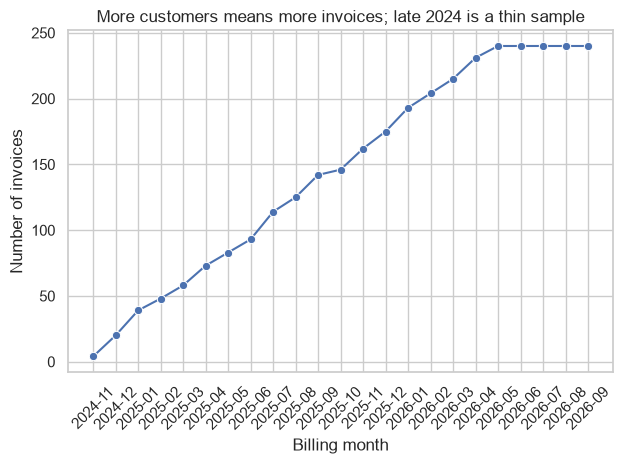

In [23]:
#| fig-cap: "Number of invoices issued each month. The book of business is growing."
fig, ax = plt.subplots()
sns.lineplot(data=monthly, x="period", y="n_invoices", marker="o", ax=ax)
ax.set_xlabel("Billing month")
ax.set_ylabel("Number of invoices")
ax.set_title("More customers means more invoices; late 2024 is a thin sample")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- `sns.lineplot` connects values in the order of `x`.
- `marker="o"` puts a point on each month so that we can see the thin early sample.
- `plt.xticks(rotation=45)` tilts the month labels so they do not overlap.
- `tight_layout()` reduces clipped labels.

**Interpretation.** Early months have very few invoices. A 25% outstanding rate in November 2024 would be one invoice. We should not start a trend story in the left-hand side of this plot.

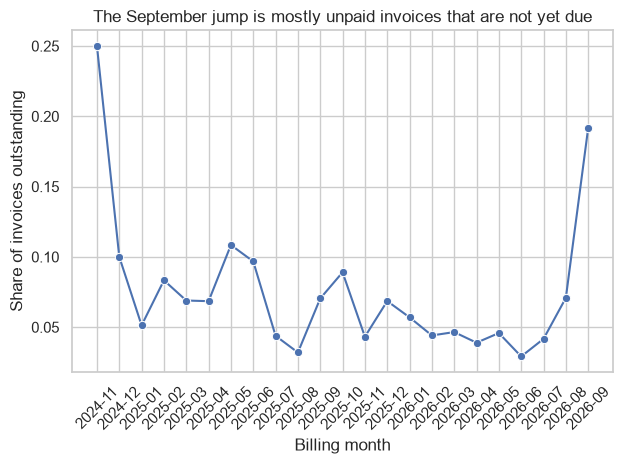

In [24]:
#| fig-cap: "Outstanding rate by billing month. September 2026 is the current snapshot month."
fig, ax = plt.subplots()
sns.lineplot(data=monthly, x="period", y="outstanding_rate", marker="o", ax=ax)
ax.set_xlabel("Billing month")
ax.set_ylabel("Share of invoices outstanding")
ax.set_title("The September jump is mostly unpaid invoices that are not yet due")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
monthly.loc[monthly["period"] >= "2026-06", ["period", "n_invoices", "n_unpaid", "n_overdue", "outstanding_rate"]]

,period,n_invoices,n_unpaid,n_overdue,outstanding_rate
19,2026-06,240,0,7,0.029167
20,2026-07,240,0,10,0.041667
21,2026-08,240,0,17,0.070833
22,2026-09,240,45,1,0.191667


**Interpretation.** September 2026 looks alarming if we only read the rate (around 19%). The breakdown is different: 45 invoices are **unpaid** and 1 is overdue, out of 240. The extract date is 12 September; September due dates are mostly 15 September. Those 45 unpaid invoices are, for a large part, **still inside the payment window**. August, by contrast, has no unpaid invoices and 17 overdue: the window has closed.

A graph of “outstanding rate” that does not split unpaid from overdue would push finance to treat the current month as a crisis. The honest sentence is: *open items in the current cycle are expected; the stock of overdue invoices from earlier months is the collection problem.*

### CRM activity looks decisive — until we ask how it is produced

Outstanding invoices have many more CRM contacts than paid ones.

In [26]:
invoices.groupby("is_outstanding")[
    ["n_interactions", "n_payment_issues", "n_reminders", "n_complaints", "n_emails"]
].mean()

,n_interactions,n_payment_issues,n_reminders,n_complaints,n_emails
is_outstanding,,,,,
False,0.165701,0.000000,0.000000,0.000000,0.116474
True,2.640553,0.995392,0.741935,0.493088,0.990783


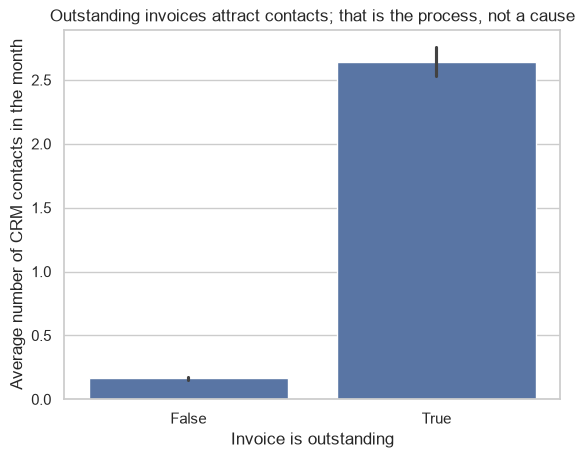

In [27]:
#| fig-cap: "CRM contacts in the invoice month, by whether the invoice is outstanding."
fig, ax = plt.subplots()
sns.barplot(
    data=invoices,
    x="is_outstanding",
    y="n_interactions",
    errorbar=("ci", 95),
    ax=ax,
)
ax.set_xlabel("Invoice is outstanding")
ax.set_ylabel("Average number of CRM contacts in the month")
ax.set_title("Outstanding invoices attract contacts; that is the process, not a cause")
plt.show()

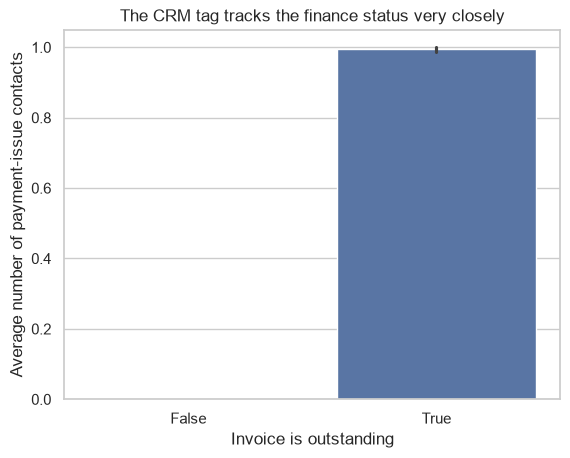

In [28]:
#| fig-cap: "Payment-issue flags are almost confined to outstanding invoices."
fig, ax = plt.subplots()
sns.barplot(
    data=invoices,
    x="is_outstanding",
    y="n_payment_issues",
    errorbar=("ci", 95),
    ax=ax,
)
ax.set_xlabel("Invoice is outstanding")
ax.set_ylabel("Average number of payment-issue contacts")
ax.set_title("The CRM tag tracks the finance status very closely")
plt.show()

**Interpretation.** The association is extremely strong. In this table, payment-issue contacts appear almost only when the invoice is outstanding. That is what we should expect from HarborLink’s **process**: reminders and “please check my payment” emails are triggered by an open invoice. They are not independent evidence that “emails cause non-payment”. Among other readings of the same numbers, contacts tagged as complaints are also a weak extra signal of risk.

A scatterplot of the same idea, with a little jitter so that overlapping points separate:

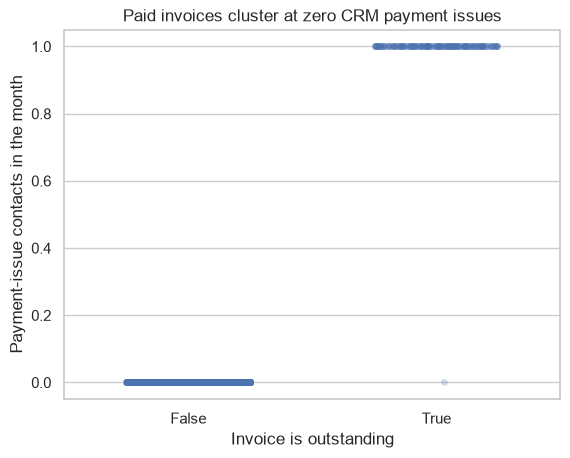

In [29]:
#| fig-cap: "Payment-issue contacts versus outstanding status. Points are invoices."
fig, ax = plt.subplots()
sns.stripplot(
    data=invoices,
    x="is_outstanding",
    y="n_payment_issues",
    jitter=0.25,
    alpha=0.25,
    ax=ax,
)
ax.set_xlabel("Invoice is outstanding")
ax.set_ylabel("Payment-issue contacts in the month")
ax.set_title("Paid invoices cluster at zero CRM payment issues")
plt.show()

- `sns.stripplot` draws one point per row.
- `jitter` moves points slightly left/right so they are not all on top of each other.
- `alpha=0.25` makes points translucent: dense regions look darker.

Paid invoices sit on zero. Outstanding invoices sit on one or more. The picture confirms the table. It does not add a new mechanism.

### Put Elena back in the picture

A good EDA does not lose the original case in the averages.

In [30]:
elena = invoices.loc[invoices["customer_id"] == 1827].sort_values("invoice_date")
elena[["period", "amount", "payment_status", "days_to_pay", "paid_after_due", "is_outstanding"]]

,period,amount,payment_status,days_to_pay,paid_after_due,is_outstanding
111,2025-03,49.9,overdue,NaN,False,True
169,2025-04,49.9,paid,12.0,False,False
242,2025-05,49.9,paid,21.0,True,False
325,2025-06,49.9,overdue,NaN,False,True
418,2025-07,49.9,paid,12.0,False,False
532,2025-08,49.9,paid,19.0,True,False
657,2025-09,49.9,paid,24.0,True,False
799,2025-10,49.9,overdue,NaN,False,True
945,2025-11,49.9,paid,23.0,True,False
1107,2025-12,49.9,paid,24.0,True,False


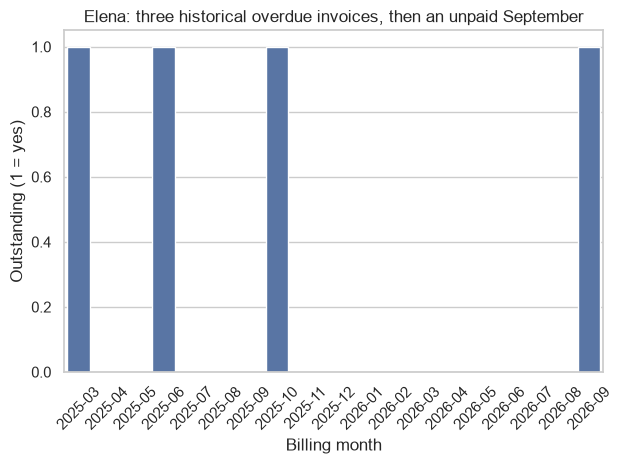

In [31]:
#| fig-cap: "Elena Vargas: outstanding flag across billing months."
fig, ax = plt.subplots()
sns.barplot(data=elena, x="period", y="is_outstanding", ax=ax)
ax.set_xlabel("Billing month")
ax.set_ylabel("Outstanding (1 = yes)")
ax.set_title("Elena: three historical overdue invoices, then an unpaid September")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretation.** Elena’s history is mixed, and the status labels must be read with the definitions above. March, June and October 2025 are `overdue`: those three invoices still have no `payment_date` in the table, so they were not recorded as paid at all, even long after the due date. That is not the same as her many `paid` invoices with `paid_after_due = True`, which *were* collected, only after the due date. September 2026 is `unpaid`: the due date has not yet passed. A current-cycle reminder is still relevant for September, but the three uncollected historical invoices are already part of the overdue stock.

### A short briefing for finance

A responsible summary is limited.

What the graphs support:

- Most invoices are paid, typically within two weeks.
- About 6.5% of all invoices in the panel are outstanding; overdue invoices from closed months are the true collection backlog.
- The September spike is largely unpaid invoices still inside the due window.
- SMB creates most of the outstanding **volume** because it is the largest segment, not because its rate is dramatically worse.
- Premium looks slightly safer; country differences are small and should not drive a strategy on their own.
- CRM payment-issue tags follow open invoices. 

What the graphs do **not** support:

- A claim that emails cause late payment.
- A claim that one country “does not pay”.
- A forecast, a causal model, or a machine-learning score.

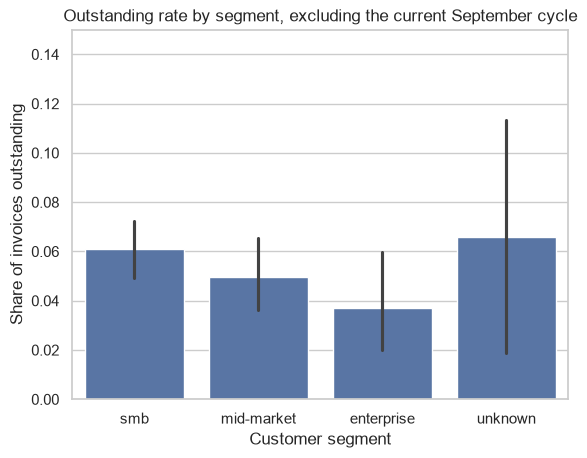

In [32]:
Path("figures").mkdir(exist_ok=True)
fig, ax = plt.subplots()
sns.barplot(
    data=invoices.loc[invoices["period"] < "2026-09"],
    x="segment",
    y="is_outstanding",
    order=["smb", "mid-market", "enterprise", "unknown"],
    errorbar=("ci", 95),
    ax=ax,
)
ax.set_xlabel("Customer segment")
ax.set_ylabel("Share of invoices outstanding")
ax.set_title("Outstanding rate by segment, excluding the current September cycle")
ax.set_ylim(0, 0.15)
fig.savefig("figures/outstanding_rate_by_segment.png", dpi=120, bbox_inches="tight")
plt.show()

`savefig` writes the figure to disk. `dpi=120` sets the resolution. `bbox_inches="tight"` crops unused margins. The last command is useful when the graph must leave the notebook and enter a slide. We excluded September so that the briefing is not dominated by invoices that are not yet due.

### A profile for one customer

The graphs above describe **the table**. Finance also asks: where does **this** customer sit? The helper `plot_customer_profile` takes a `customer_name` or a `customer_id` and draws two blocks.

1. **Above:** every invoice of that customer on a time line. A blue point is `paid`; a red point is `unpaid` or `overdue`.
2. **Below:** one small plot per variable that still makes sense at customer level. Invoice identifiers and dates (`invoice_id`, `period`, `payment_status`, …) are dropped. Attributes such as country or plan are kept. Amounts and delays become **means** for that customer; CRM counts become **sums**; `days_to_pay` is the mean over invoices that have a payment date. Each small plot is the distribution of that summary **across all customers**, with this customer marked (red point or highlighted bar) and the value written under the panel.

Change the argument and re-run the cell.

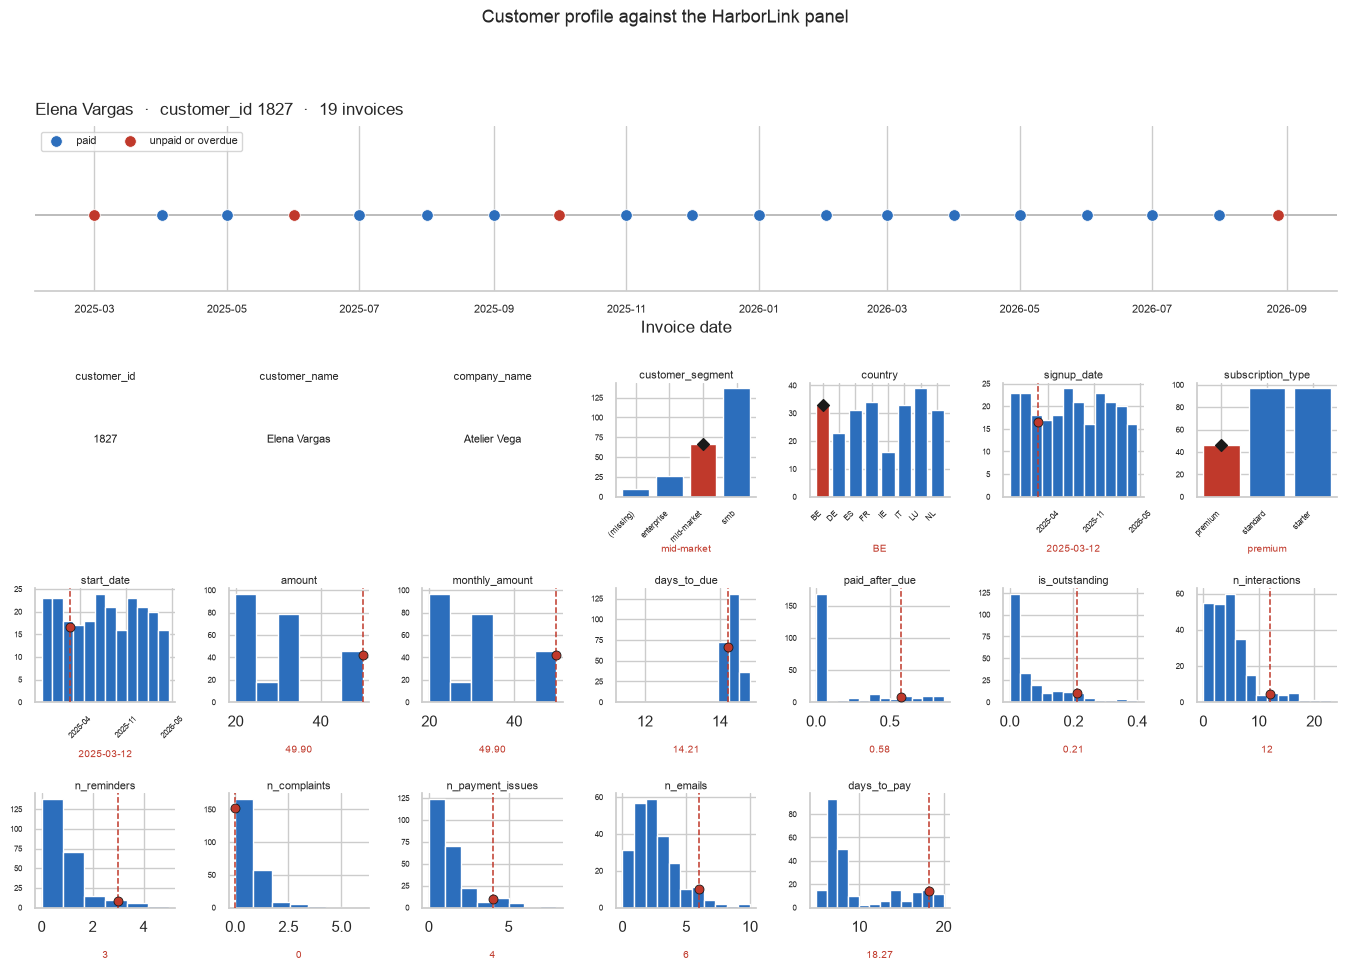

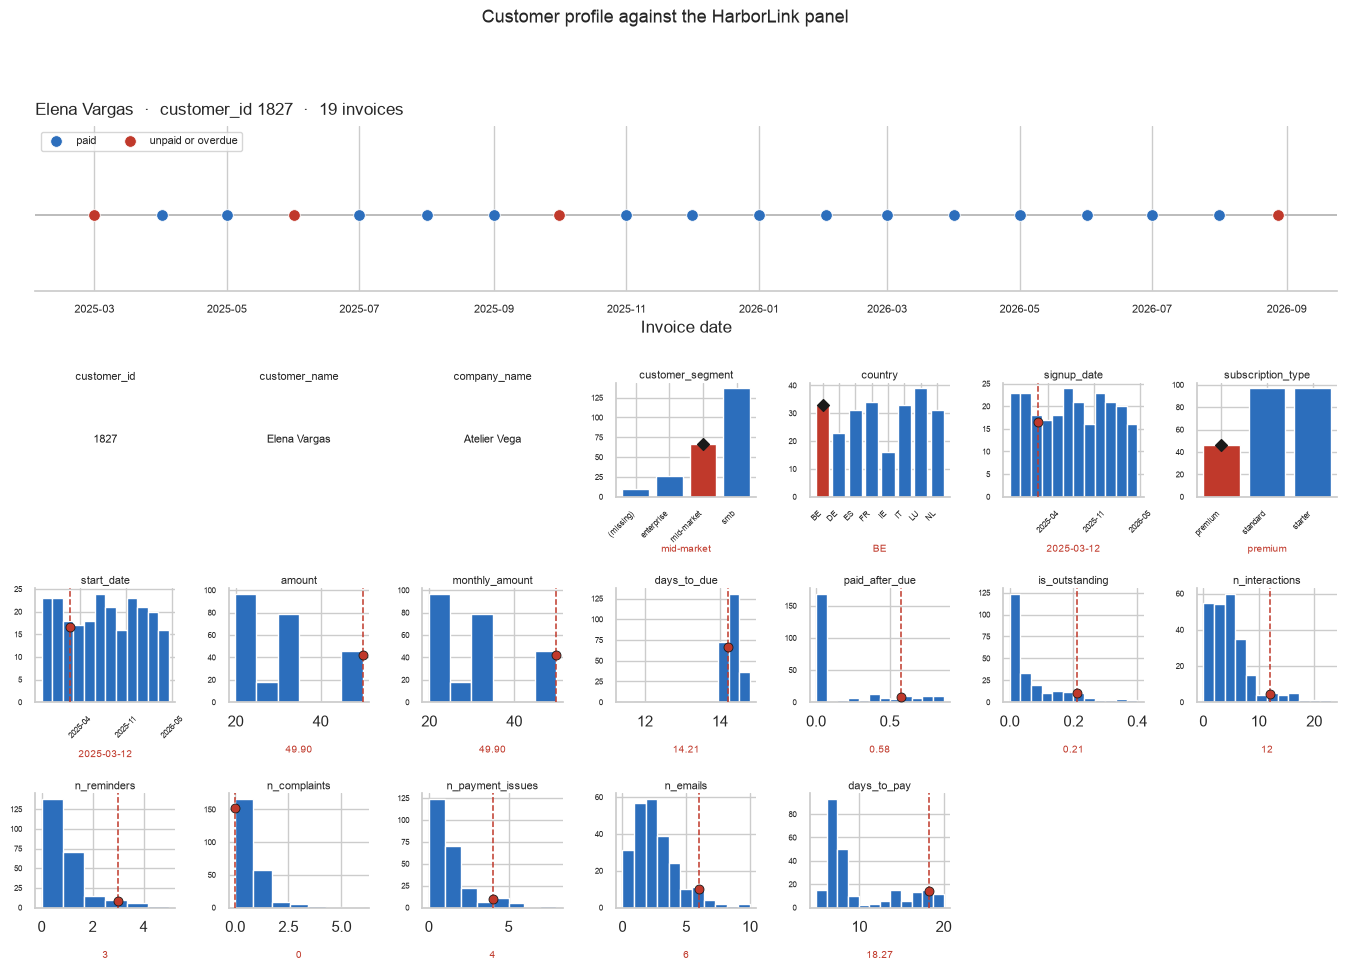

In [33]:
#| fig-width: 16
#| fig-height: 11
from python.customer_profile import plot_customer_profile

plot_customer_profile("Elena Vargas", invoices)

The same figure with the identifier:

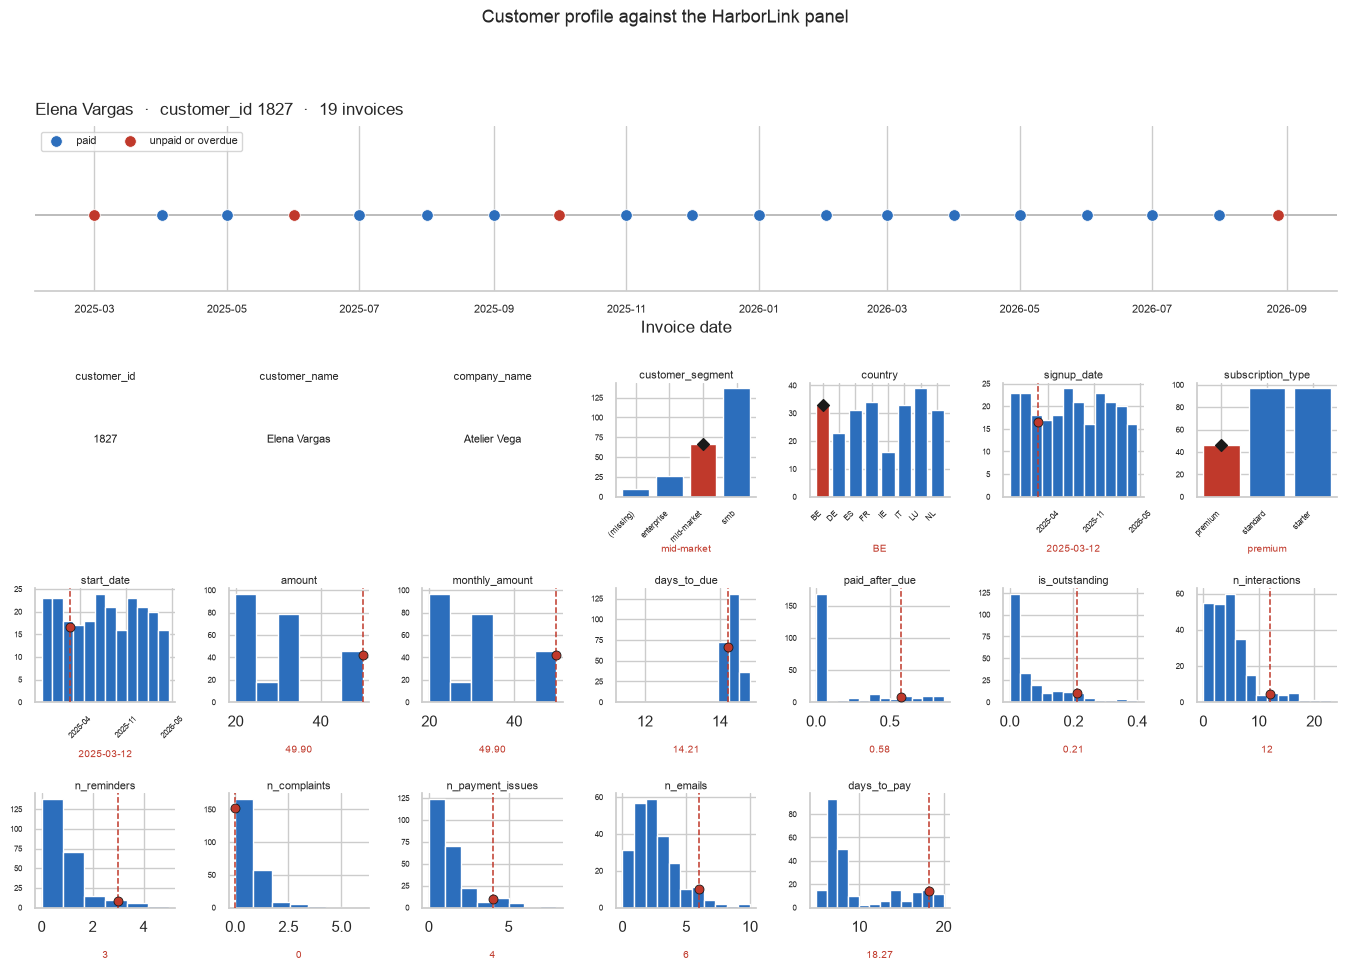

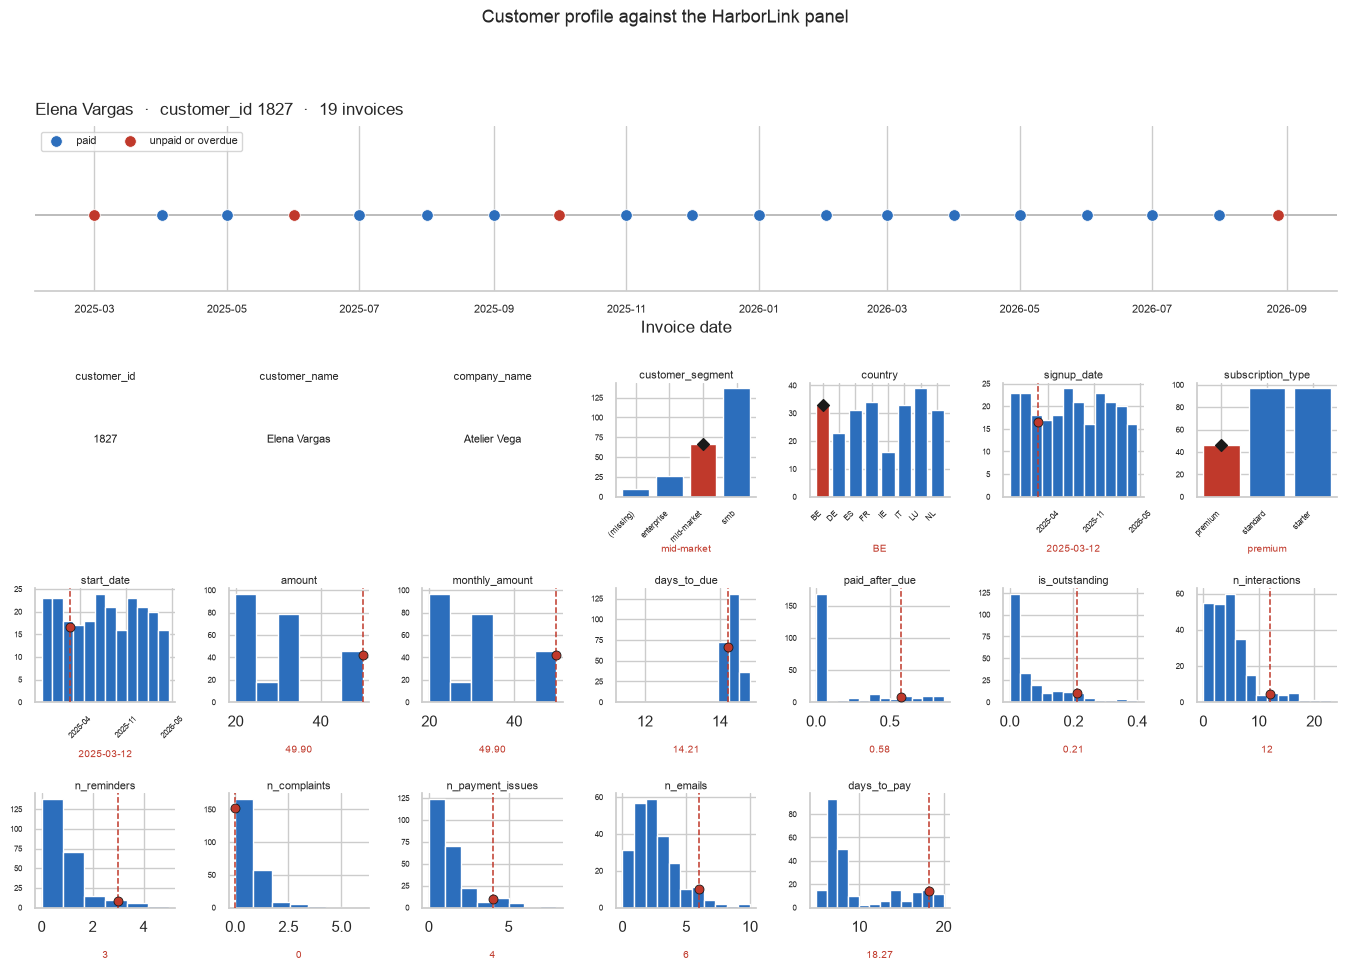

In [34]:
#| fig-width: 16
#| fig-height: 11
plot_customer_profile(1827, invoices)

### Towards statistical analysis

We now have pictures of volume, risk, speed, time and process. Some comparisons are small. Some charts mainly repeat a status that is already in the finance file.

The natural next step is not another gallery of charts. It is to choose an outcome (for example, overdue after the due date), choose covariates that are known **before** the outcome, and estimate associations with uncertainty. Visualisation remains the way those models are checked. It is no longer the whole analysis.

The path remains:

**Heterogeneous sources → one invoice-level DataFrame → exploratory analysis and visualisation → statistical and machine-learning analysis**